In [ ]:
print("Hello")

Hello


To **access APIs using Python**, the most common way is to use the built-in `requests` library. Below are simple examples showing how to work with APIs.

---

# 1️⃣ Install Required Library

First install the `requests` module:

```bash
pip install requests
```

---

# 2️⃣ Simple API GET Request

This example fetches data from a public API.

```python
import requests

# API endpoint
url = "https://jsonplaceholder.typicode.com/posts/1"

# Send GET request
response = requests.get(url)

# Check status code
if response.status_code == 200:
    data = response.json()
    print("API Response:")
    print(data)
else:
    print("Failed to fetch data:", response.status_code)
```

Output example:

```
API Response:
{
 'userId': 1,
 'id': 1,
 'title': 'sunt aut facere...',
 'body': 'quia et suscipit...'
}
```

---

# 3️⃣ GET Request with Parameters

Some APIs require query parameters.

```python
import requests

url = "https://api.github.com/search/repositories"

params = {
    "q": "network automation",
    "sort": "stars"
}

response = requests.get(url, params=params)

data = response.json()

for repo in data["items"][:5]:
    print(repo["name"], "-", repo["html_url"])
```

---

# 4️⃣ POST Request Example

Used when sending data to an API.

```python
import requests

url = "https://jsonplaceholder.typicode.com/posts"

payload = {
    "title": "Network Automation",
    "body": "Using Python APIs",
    "userId": 1
}

response = requests.post(url, json=payload)

print("Status:", response.status_code)
print("Response:", response.json())
```

---

# 5️⃣ API with Authentication (Token Example)

```python
import requests

url = "https://api.github.com/user"

headers = {
    "Authorization": "Bearer YOUR_TOKEN_HERE"
}

response = requests.get(url, headers=headers)

print(response.json())
```

---

# 6️⃣ Real Network Engineer Example

Example: **Check device API status**

```python
import requests

url = "http://192.168.1.1/api/v1/interfaces"

headers = {
    "Authorization": "Bearer mytoken123"
}

response = requests.get(url, headers=headers, verify=False)

interfaces = response.json()

for interface in interfaces:
    print(interface["name"], interface["status"])
```

---

💡 Since you are a **Cloud Network Engineer**, APIs are used heavily with:

* Network automation
* Arista eAPI
* Cisco RESTCONF
* AWS APIs
* Azure APIs
* Monitoring tools

---

✅ If you want, I can also show you **real network automation examples** like:

* Python script to call **Arista eAPI**
* Python script for **Cisco RESTCONF**
* Python script to **collect interface stats from switches**
* Python script to **run network tests automatically**

These are **very useful for Network Engineer interviews (Amazon / cloud roles)**.


Since you work with **Arista switches and automation** (based on your recent troubleshooting with Arista devices), these Python examples will be **very useful for network engineering automation and interviews**. Below are **realistic scripts used by network engineers**.

---

# 1️⃣ Python Script to Call **Arista eAPI**

Arista switches use **eAPI (JSON-RPC)**.

```python
import requests
import json

switch_ip = "192.168.1.10"
username = "admin"
password = "admin"

url = f"https://{switch_ip}/command-api"

headers = {"Content-Type": "application/json"}

payload = {
    "jsonrpc": "2.0",
    "method": "runCmds",
    "params": {
        "version": 1,
        "cmds": ["show version", "show interfaces status"],
        "format": "json"
    },
    "id": 1
}

response = requests.post(url,
                         auth=(username, password),
                         headers=headers,
                         data=json.dumps(payload),
                         verify=False)

data = response.json()

print("Switch Version:")
print(data["result"][0]["version"])

print("\nInterfaces:")
for intf in data["result"][1]["interfaceStatuses"]:
    print(intf)
```

📌 This will retrieve:

* Switch version
* Interface status

---

# 2️⃣ Python Script for **Cisco RESTCONF**

RESTCONF is used with Cisco IOS-XE devices.

```python
import requests
import json

device = "192.168.1.20"
username = "admin"
password = "admin"

url = f"https://{device}/restconf/data/ietf-interfaces:interfaces"

headers = {
    "Accept": "application/yang-data+json"
}

response = requests.get(url,
                        auth=(username, password),
                        headers=headers,
                        verify=False)

interfaces = response.json()

for interface in interfaces["ietf-interfaces:interfaces"]["interface"]:
    print("Interface:", interface["name"])
    print("Type:", interface["type"])
    print()
```

📌 Retrieves:

* Interface names
* Interface types

---

# 3️⃣ Python Script to **Collect Interface Stats from Switches**

This example collects **interface counters**.

```python
import requests
import json

switch = "192.168.1.10"

url = f"https://{switch}/command-api"

payload = {
 "jsonrpc": "2.0",
 "method": "runCmds",
 "params": {
  "version": 1,
  "cmds": ["show interfaces counters"],
  "format": "json"
 },
 "id": 1
}

response = requests.post(url,
                         auth=("admin","admin"),
                         json=payload,
                         verify=False)

data = response.json()

interfaces = data["result"][0]["interfaces"]

for intf in interfaces:
    stats = interfaces[intf]
    print(f"Interface: {intf}")
    print(f"RX Packets: {stats['inPkts']}")
    print(f"TX Packets: {stats['outPkts']}")
    print(f"RX Errors: {stats['inErrors']}")
    print()
```

📌 Useful for:

* Network monitoring
* Capacity planning
* Automation dashboards

---

# 4️⃣ Python Script to **Run Network Tests Automatically**

This script performs **ping tests across multiple devices**.

```python
import subprocess

devices = [
    "8.8.8.8",
    "1.1.1.1",
    "192.168.1.1",
    "192.168.1.10"
]

def ping_test(ip):

    result = subprocess.run(
        ["ping", "-c", "3", ip],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        print(f"{ip} reachable")
    else:
        print(f"{ip} unreachable")

for device in devices:
    ping_test(device)
```

📌 Useful for:

* Network monitoring
* CI/CD network validation
* Automated health checks

---

# 5️⃣ Advanced Network Test Automation Example

You can also automate **latency testing**.

```python
import subprocess

devices = ["8.8.8.8", "1.1.1.1"]

for ip in devices:

    result = subprocess.run(
        ["ping", "-c", "4", ip],
        capture_output=True,
        text=True
    )

    output = result.stdout

    for line in output.split("\n"):
        if "avg" in line:
            print(ip, line)
```

---

# 🚀 Real Network Automation Project Example

Network engineers combine these scripts to build:

```
network_automation/
│
├── device_inventory.json
├── collect_stats.py
├── run_health_checks.py
├── arista_api.py
└── report_generator.py
```

This system can:

* Pull switch metrics
* Run connectivity tests
* Generate reports
* Alert on failures

---

✅ If you want, I can also show **3 extremely useful scripts for network engineers**:

1️⃣ **Python script to backup configs from 100 switches automatically**
2️⃣ **Python script to detect BGP failures automatically**
3️⃣ **Python script to build a network topology map automatically**

These are **very powerful scripts used in companies like Amazon, Microsoft, and cloud networking teams.**


In [1]:
!pip install subprocess

Defaulting to user installation because normal site-packages is not writeable


ERROR: Could not find a version that satisfies the requirement subprocess (from versions: none)

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: C:\Users\v-yaalam\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for subprocess


In [2]:
import subprocess

devices = ["8.8.8.8", "1.1.1.1"]

for ip in devices:

    result = subprocess.run(
        ["ping", "-c", "4", ip],
        capture_output=True,
        text=True
    )

    output = result.stdout

    for line in output.split("\n"):
        if "avg" in line:
            print(ip, line)


https://requests.readthedocs.io/en/stable/user/quickstart/?utm_source=openai


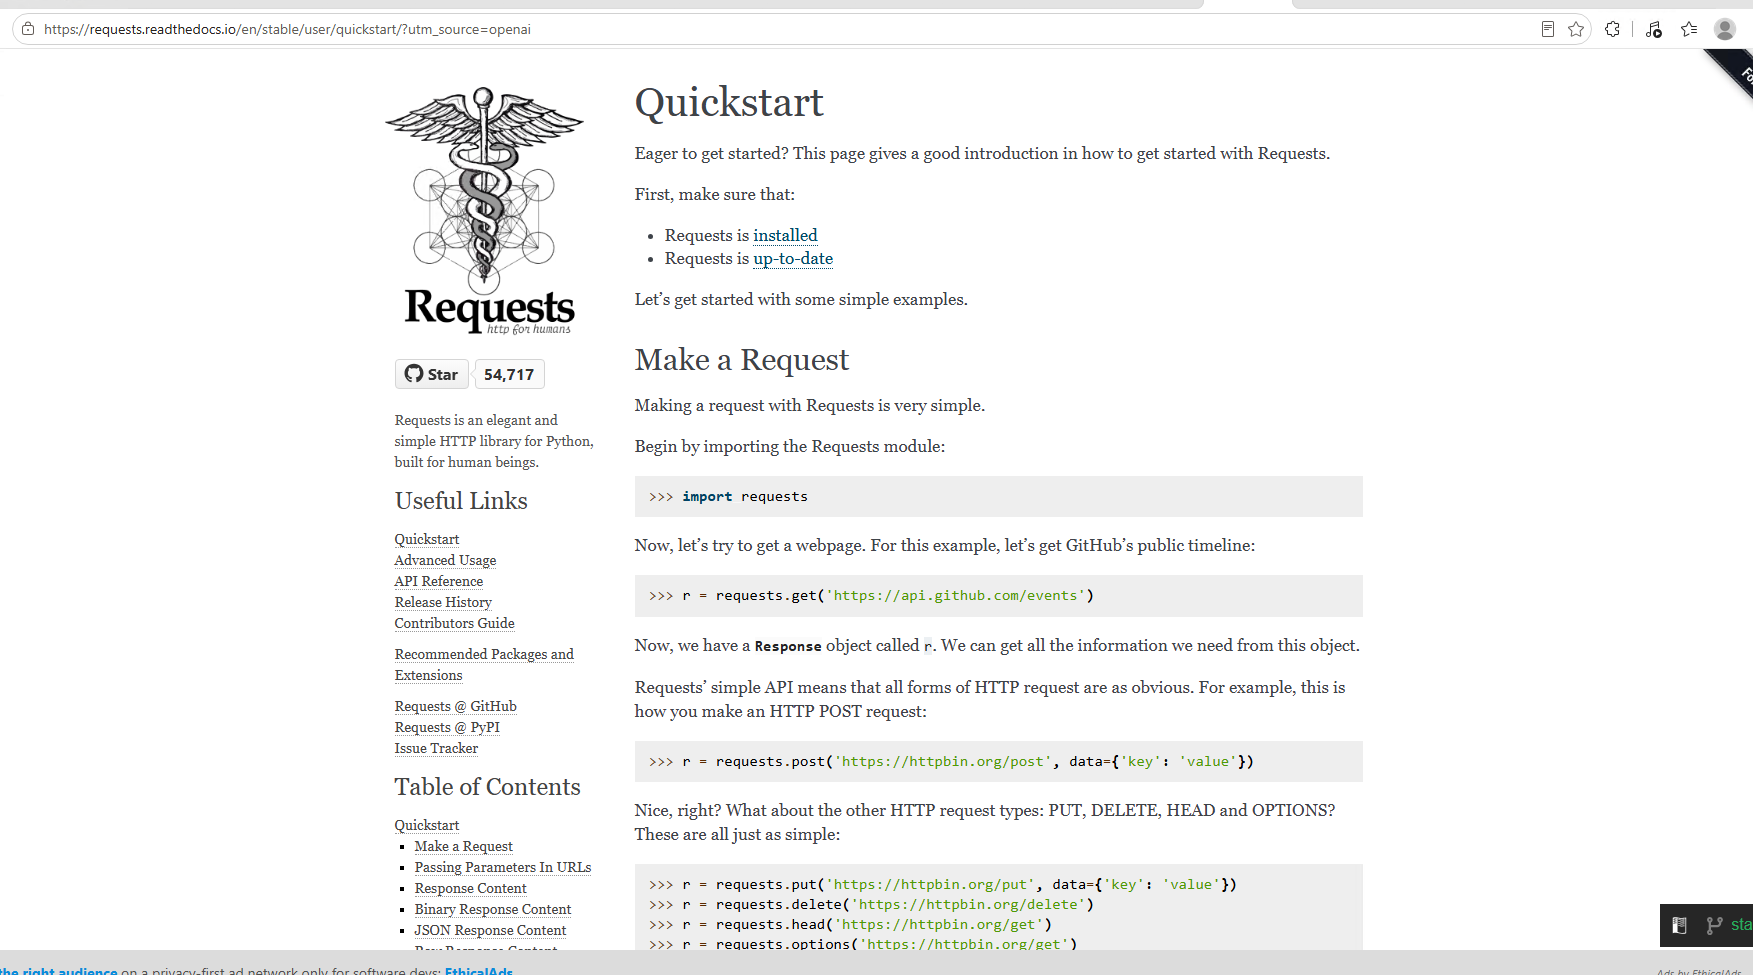











In [1]:
!pip install requests

Looking in indexes: https://packagefeedproxy.microsoft.io/pypi/simple/



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import requests

In [10]:
r = requests.get('https://api.github.com/events')

print(r.status_code)
print(r.json())

403
{'message': "API rate limit exceeded for 20.236.10.129. (But here's the good news: Authenticated requests get a higher rate limit. Check out the documentation for more details.)", 'documentation_url': 'https://docs.github.com/rest/overview/resources-in-the-rest-api#rate-limiting'}


In [11]:
import requests

def get_github_events():
    r = requests.get('https://api.github.com/events')
    return r

response = get_github_events()

print(response.status_code)
print(response.json())

200
[{'id': '25251890320', 'type': 'PushEvent', 'actor': {'id': 87637612, 'login': 'NewbieXvwu', 'display_login': 'NewbieXvwu', 'gravatar_id': '', 'url': 'https://api.github.com/users/NewbieXvwu', 'avatar_url': 'https://avatars.githubusercontent.com/u/87637612?'}, 'repo': {'id': 1389396599, 'name': 'NewbieXvwu/PvZ-Portable', 'url': 'https://api.github.com/repos/NewbieXvwu/PvZ-Portable'}, 'payload': {'repository_id': 1389396599, 'push_id': 47818175488, 'ref': 'refs/heads/deploy15', 'head': 'ed689ac2a7d6f738b2d7a23f6cc5f10359372c6b', 'before': '7a9052ef687a0f137bf718d0f45383a6e092733f'}, 'public': True, 'created_at': '2026-10-26T11:45:14Z'}, {'id': '25251890332', 'type': 'PushEvent', 'actor': {'id': 7744963, 'login': 'lesichkovm', 'display_login': 'lesichkovm', 'gravatar_id': '', 'url': 'https://api.github.com/users/lesichkovm', 'avatar_url': 'https://avatars.githubusercontent.com/u/7744963?'}, 'repo': {'id': 1427623046, 'name': 'dracory/statsadmin', 'url': 'https://api.github.com/repos/

In [12]:
r = requests.post('https://httpbin.org/post', data={'key': 'value'})

print(r.status_code)
print(r.json())

200
{'args': {}, 'data': '', 'files': {}, 'form': {'key': 'value'}, 'headers': {'Accept': '*/*', 'Accept-Encoding': 'gzip, deflate, zstd', 'Content-Length': '9', 'Content-Type': 'application/x-www-form-urlencoded', 'Host': 'httpbin.org', 'User-Agent': 'python-requests/2.34.2', 'X-Amzn-Trace-Id': 'Root=1-6adfa0c6-07702e9a4d75f7381be5435d'}, 'json': None, 'origin': '70.37.26.37', 'url': 'https://httpbin.org/post'}


In [13]:
r = requests.put('https://httpbin.org/put', data={'key': 'value'})

print(r.status_code)
print(r.json())

200
{'args': {}, 'data': '', 'files': {}, 'form': {'key': 'value'}, 'headers': {'Accept': '*/*', 'Accept-Encoding': 'gzip, deflate, zstd', 'Content-Length': '9', 'Content-Type': 'application/x-www-form-urlencoded', 'Host': 'httpbin.org', 'User-Agent': 'python-requests/2.34.2', 'X-Amzn-Trace-Id': 'Root=1-6adfa0ca-11ee8c953f3b7e5f13f3b305'}, 'json': None, 'origin': '70.37.26.37', 'url': 'https://httpbin.org/put'}


In [14]:
r = requests.delete('https://httpbin.org/delete')

print(r.status_code)
print(r.json())

200
{'args': {}, 'data': '', 'files': {}, 'form': {}, 'headers': {'Accept': '*/*', 'Accept-Encoding': 'gzip, deflate, zstd', 'Content-Length': '0', 'Host': 'httpbin.org', 'User-Agent': 'python-requests/2.34.2', 'X-Amzn-Trace-Id': 'Root=1-6adfa0cd-6258d42272eb86472317833c'}, 'json': None, 'origin': '70.37.26.34', 'url': 'https://httpbin.org/delete'}


In [16]:
r = requests.head('https://httpbin.org/get')

print(r.status_code)



200


In [17]:
r = requests.options('https://httpbin.org/get')

print(r.status_code)
print(r.json())

200


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [19]:
payload = {'key1': 'value1', 'key2': 'value2'}
r = requests.get('https://httpbin.org/get', params=payload)

print(r.status_code)
print(r.json())

200
{'args': {'key1': 'value1', 'key2': 'value2'}, 'headers': {'Accept': '*/*', 'Accept-Encoding': 'gzip, deflate, zstd', 'Host': 'httpbin.org', 'User-Agent': 'python-requests/2.34.2', 'X-Amzn-Trace-Id': 'Root=1-6adfa108-3549e5dc01ddef94095b3a87'}, 'origin': '70.37.26.40', 'url': 'https://httpbin.org/get?key1=value1&key2=value2'}


In [20]:
print(r.url)

https://httpbin.org/get?key1=value1&key2=value2


In [21]:
payload = {'key1': 'value1', 'key2': ['value2', 'value3']}

r = requests.get('https://httpbin.org/get', params=payload)
print(r.url)

https://httpbin.org/get?key1=value1&key2=value2&key2=value3


In [22]:
import requests

r = requests.get('https://api.github.com/events')
r.text

'{"message":"API rate limit exceeded for 20.236.11.185. (But here\'s the good news: Authenticated requests get a higher rate limit. Check out the documentation for more details.)","documentation_url":"https://docs.github.com/rest/overview/resources-in-the-rest-api#rate-limiting"}\n'

In [23]:
r.content

b'{"message":"API rate limit exceeded for 20.236.11.185. (But here\'s the good news: Authenticated requests get a higher rate limit. Check out the documentation for more details.)","documentation_url":"https://docs.github.com/rest/overview/resources-in-the-rest-api#rate-limiting"}\n'

In [24]:
!pip install PIL

Looking in indexes: https://packagefeedproxy.microsoft.io/pypi/simple/


ERROR: Could not find a version that satisfies the requirement PIL (from versions: none)

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for PIL


In [25]:
!pip install io

Looking in indexes: https://packagefeedproxy.microsoft.io/pypi/simple/


ERROR: Could not find a version that satisfies the requirement io (from versions: none)

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for io


In [26]:
from PIL import Image

from io import BytesIO

i = Image.open(BytesIO(r.content))

ModuleNotFoundError: No module named 'PIL'

In [27]:
r = requests.get('https://api.github.com/events', stream=True)

r.raw

In [28]:
r = requests.get('https://api.github.com/events', stream=True)

r.raw.read(10)

b'\x1f\x8b\x08\x00\x00\x00\x00\x00\x00\x03'

In [30]:
url = 'https://api.github.com/some/endpoint'
headers = {'user-agent': 'my-app/0.0.1'}

r = requests.get(url, headers=headers)

print(r)

<Response [404]>


In [31]:
payload = {'key1': 'value1', 'key2': 'value2'}

r = requests.post('https://httpbin.org/post', data=payload)
print(r.text)

{
  "args": {}, 
  "data": "", 
  "files": {}, 
  "form": {
    "key1": "value1", 
    "key2": "value2"
  }, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate, zstd", 
    "Content-Length": "23", 
    "Content-Type": "application/x-www-form-urlencoded", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6adfa25e-15399b61473792ac5a34ed22"
  }, 
  "json": null, 
  "origin": "70.37.26.37", 
  "url": "https://httpbin.org/post"
}



In [33]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.text)

print(r2.text)

{
  "args": {}, 
  "data": "", 
  "files": {}, 
  "form": {
    "key1": [
      "value1", 
      "value2"
    ]
  }, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate, zstd", 
    "Content-Length": "23", 
    "Content-Type": "application/x-www-form-urlencoded", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6adfa27c-5a428ef42a3f6fbc62f371ba"
  }, 
  "json": null, 
  "origin": "70.37.26.40", 
  "url": "https://httpbin.org/post"
}

{
  "args": {}, 
  "data": "", 
  "files": {}, 
  "form": {
    "key1": [
      "value1", 
      "value2"
    ]
  }, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate, zstd", 
    "Content-Length": "23", 
    "Content-Type": "application/x-www-form-urlencoded", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6adfa27d-5cf3d86435ad86896eb519ae"
  }, 
  "json": null, 
  "origin": "70.37.26.34", 
  "

In [34]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.text)

#print(r2.text)

{
  "args": {}, 
  "data": "", 
  "files": {}, 
  "form": {
    "key1": [
      "value1", 
      "value2"
    ]
  }, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate, zstd", 
    "Content-Length": "23", 
    "Content-Type": "application/x-www-form-urlencoded", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6adfa285-045979f4415f50794d23f0e8"
  }, 
  "json": null, 
  "origin": "70.37.26.38", 
  "url": "https://httpbin.org/post"
}



In [35]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1)

#print(r2.text)

<Response [200]>


In [36]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.content)

#print(r2.text)

b'{\n  "args": {}, \n  "data": "", \n  "files": {}, \n  "form": {\n    "key1": [\n      "value1", \n      "value2"\n    ]\n  }, \n  "headers": {\n    "Accept": "*/*", \n    "Accept-Encoding": "gzip, deflate, zstd", \n    "Content-Length": "23", \n    "Content-Type": "application/x-www-form-urlencoded", \n    "Host": "httpbin.org", \n    "User-Agent": "python-requests/2.34.2", \n    "X-Amzn-Trace-Id": "Root=1-6adfa29e-355eded6790dd216271ea6c6"\n  }, \n  "json": null, \n  "origin": "70.37.26.36", \n  "url": "https://httpbin.org/post"\n}\n'


In [37]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.connection)

#print(r2.text)

In [38]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.content)

#print(r2.text)

b'{\n  "args": {}, \n  "data": "", \n  "files": {}, \n  "form": {\n    "key1": [\n      "value1", \n      "value2"\n    ]\n  }, \n  "headers": {\n    "Accept": "*/*", \n    "Accept-Encoding": "gzip, deflate, zstd", \n    "Content-Length": "23", \n    "Content-Type": "application/x-www-form-urlencoded", \n    "Host": "httpbin.org", \n    "User-Agent": "python-requests/2.34.2", \n    "X-Amzn-Trace-Id": "Root=1-6adfa2bc-68923026311264f235a8a349"\n  }, \n  "json": null, \n  "origin": "70.37.26.40", \n  "url": "https://httpbin.org/post"\n}\n'


In [39]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.cookies)

#print(r2.text)

<RequestsCookieJar[]>


In [40]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.headers)

#print(r2.text)

{'Date': 'Mon, 26 Oct 2026 18:58:36 GMT', 'Content-Type': 'application/json', 'Content-Length': '517', 'Connection': 'keep-alive', 'Server': 'gunicorn/19.9.0', 'Access-Control-Allow-Origin': '*', 'Access-Control-Allow-Credentials': 'true'}


In [41]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.history)

#print(r2.text)

[]


In [42]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.json)

#print(r2.text)

<bound method Response.json of <Response [200]>>


In [43]:
payload_tuples = [('key1', 'value1'), ('key1', 'value2')]
r1 = requests.post('https://httpbin.org/post', data=payload_tuples)
payload_dict = {'key1': ['value1', 'value2']}
r2 = requests.post('https://httpbin.org/post', data=payload_dict)
print(r1.request)

#print(r2.text)

<PreparedRequest [POST]>


In [45]:
import json

url = 'https://api.github.com/some/endpoint'
payload = {'some': 'data'}

r = requests.post(url, data=json.dumps(payload))

print(r)

<Response [403]>


In [46]:
url = 'https://httpbin.org/post'
files = {'file': open('report.xls', 'rb')}

r = requests.post(url, files=files)
r.text

FileNotFoundError: [Errno 2] No such file or directory: 'report.xls'

In [47]:
url = 'https://httpbin.org/post'
files = {'file': ('report.xls', open('report.xls', 'rb'), 'application/vnd.ms-excel', {'Expires': '0'})}

r = requests.post(url, files=files)
r.text

FileNotFoundError: [Errno 2] No such file or directory: 'report.xls'

In [48]:
url = 'https://httpbin.org/post'
files = {'file': ('report.xls', open('report.xls', 'rb'), 'application/vnd.ms-excel', {'Expires': '0'})}

r = requests.post(url, files=files)
r.text

'{\n  "args": {}, \n  "data": "", \n  "files": {\n    "file": ""\n  }, \n  "form": {}, \n  "headers": {\n    "Accept": "*/*", \n    "Accept-Encoding": "gzip, deflate, zstd", \n    "Content-Length": "198", \n    "Content-Type": "multipart/form-data; boundary=8565cbdfaf53a2ea128e558a561e85aa", \n    "Host": "httpbin.org", \n    "User-Agent": "python-requests/2.34.2", \n    "X-Amzn-Trace-Id": "Root=1-6adfa38e-2e01e5522bb591dc196c93b3"\n  }, \n  "json": null, \n  "origin": "70.37.26.41", \n  "url": "https://httpbin.org/post"\n}\n'

In [49]:
url = 'https://httpbin.org/post'
files = {'file': ('report.csv', 'some,data,to,send\nanother,row,to,send\n')}

r = requests.post(url, files=files)
r.text

'{\n  "args": {}, \n  "data": "", \n  "files": {\n    "file": "some,data,to,send\\nanother,row,to,send\\n"\n  }, \n  "form": {}, \n  "headers": {\n    "Accept": "*/*", \n    "Accept-Encoding": "gzip, deflate, zstd", \n    "Content-Length": "184", \n    "Content-Type": "multipart/form-data; boundary=ea43f7df8635bfd21f3bcd3fe0ebc4ec", \n    "Host": "httpbin.org", \n    "User-Agent": "python-requests/2.34.2", \n    "X-Amzn-Trace-Id": "Root=1-6adfa3ac-38ad9b404c81026f28d7e851"\n  }, \n  "json": null, \n  "origin": "70.37.26.34", \n  "url": "https://httpbin.org/post"\n}\n'

In [52]:
r = requests.get('https://httpbin.org/get')
r.status_code

200

In [51]:
r = requests.get('https://httpbin.org/get')
r.status_code

print(r)

<Response [200]>


In [53]:
bad_r = requests.get('https://httpbin.org/status/404')
bad_r.status_code

404

In [55]:
url = 'http://example.com/some/cookie/setting/url'
r = requests.get(url)

